In [ ]:
!pip install torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cpu

Looking in indexes: https://download.pytorch.org/whl/cpu
  Using cached sympy-1.14.0-py3-none-any.whl.metadata (12 kB)
  Using cached networkx-3.6.1-py3-none-any.whl.metadata (6.8 kB)
  Using cached mpmath-1.3.0-py3-none-any.whl.metadata (8.6 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 196.3/196.3 MB 20.2 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 31.4 MB/s eta 0:00:00
Using cached networkx-3.6.1-py3-none-any.whl (2.1 MB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 10.3 MB/s eta 0:00:00
Using cached sympy-1.14.0-py3-none-any.whl (6.3 MB)
Using cached mpmath-1.3.0-py3-none-any.whl (536 kB)


In [1]:
%pip install torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cpu

Looking in indexes: https://download.pytorch.org/whl/cpu
  Using cached https://download-r2.pytorch.org/whl/cpu/torch-2.14.1%2Bcpu-cp312-cp312-manylinux_2_28_x86_64.whl.metadata (37 kB)
  Using cached https://download-r2.pytorch.org/whl/cpu/torchvision-0.29.1%2Bcpu-cp312-cp312-manylinux_2_28_x86_64.whl.metadata (5.7 kB)
  Using cached filelock-3.32.3-py3-none-any.whl.metadata (2.0 kB)
  Using cached https://download.pytorch.org/whl/setuptools-78.1.0-py3-none-any.whl.metadata (6.6 kB)
  Using cached networkx-3.6.1-py3-none-any.whl.metadata (6.8 kB)
  Using cached fsspec-2026.7.0-py3-none-any.whl.metadata (10 kB)
Using cached https://download-r2.pytorch.org/whl/cpu/torch-2.14.1%2Bcpu-cp312-cp312-manylinux_2_28_x86_64.whl (196.3 MB)
Using cached https://download-r2.pytorch.org/whl/cpu/torchvision-0.29.1%2Bcpu-cp312-cp312-manylinux_2_28_x86_64.whl (1.7 MB)
Using cached fsspec-2026.7.0-py3-none-any.whl (206 kB)
Using cached networkx-3.6.1-py3-none-any.whl (2.1 MB)
Using cached https://downl

In [2]:
import torch
import torch.nn as nn

In [3]:
class SimpleNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.layer1 = nn.Linear(in_features=10, out_features=16)
        self.activation = nn.ReLU()
        self.layer2 = nn.Linear(in_features=16, out_features=2)

    def forward(self, X):
        x = self.layer1(X)
        x = self.activation(x)
        x = self.layer2(x)
        return x

In [56]:
class AND(nn.Module):
    def __init__(self):
        super().__init__()
        self.layer1 = nn.Linear(in_features=2, out_features=1)
        self.activation = nn.Sigmoid()
    def forward(self, X):
        x = self.layer1(X)
        x = self.activation(x)
        return x

In [57]:
import torch.optim as optim

In [58]:
model = AND()
print(model)

criterion = nn.BCELoss()
optimizer = optim.SGD(model.parameters() , lr=0.1)

X = torch.tensor([[0., 0.],
                  [0., 1.],
                  [1., 0.],
                  [1., 1.]])

# Expected AND outputs: 0, 0, 0, 1
y = torch.tensor([[0.],
                  [0.],
                  [0.],
                  [1.]])

AND(
  (layer1): Linear(in_features=2, out_features=1, bias=True)
  (activation): Sigmoid()
)


In [74]:
def train(trainOptimizer , epochs):
    print("Training with lr : ", optimizer.param_groups[0]['lr'], " and epochs : ", epochs)
    for epoch in range(epochs):
        pred = model(X)
        loss = criterion(pred, y)
        trainOptimizer.zero_grad()
        loss.backward()
        trainOptimizer.step()

In [71]:
def getaccuracy():
    with torch.no_grad():
        raw_outputs = model(X)
        predictions = (raw_outputs >= 0.5).float()
        correct = (predictions == y).float()
        accuracy = correct.mean() * 100.0
        return accuracy

In [72]:
import matplotlib.pyplot as plt

def plot_metrics(x, y, title="Training Metric over Time", xlabel="X-axis", ylabel="Y-axis"):
    """A self-contained function to plot X and Y arrays/lists."""
    plt.figure(figsize=(8, 5))

    # Plot with a line and circular markers
    plt.plot(x, y, marker='o', linestyle='-', color='b')

    plt.title(title)
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.grid(True, linestyle='--', alpha=0.7)

    plt.tight_layout()
    plt.show()


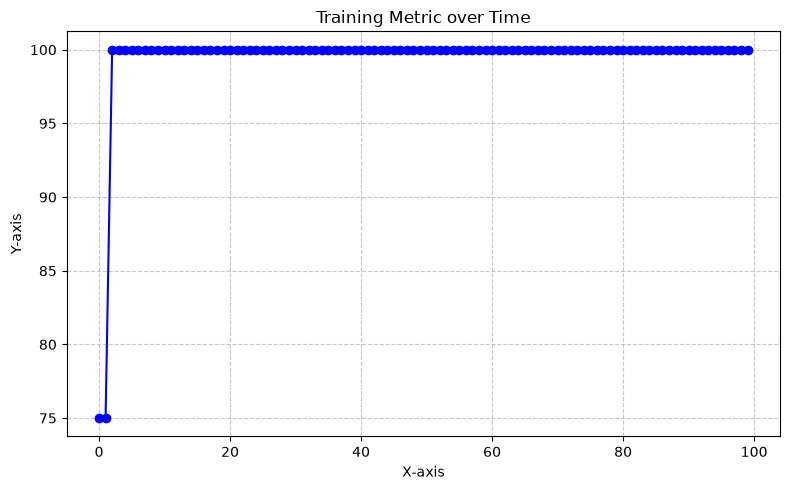

In [68]:
# 1. Re-initialize the model to reset all weights back to random
model = AND()

# 2. Re-create the optimizer so it links to the NEW model's parameters
baseLr = 1.0
optimizer = optim.SGD(model.parameters(), lr=baseLr)

trials = 100
trial_history = []
accuracy_history = []

for trial in range(trials):
    newLr = baseLr * 0.9
    baseLr = newLr
    optimizer.param_groups[0]['lr'] = newLr

    train(optimizer, 1000)

    current_acc = getaccuracy()
    trial_history.append(trial)
    accuracy_history.append(current_acc)

plot_metrics(x=trial_history, y=accuracy_history)

Training with lr :  0.001  and epochs :  1
Training with lr :  0.001  and epochs :  10
Training with lr :  0.001  and epochs :  100
Training with lr :  0.001  and epochs :  1000
Training with lr :  0.001  and epochs :  10000


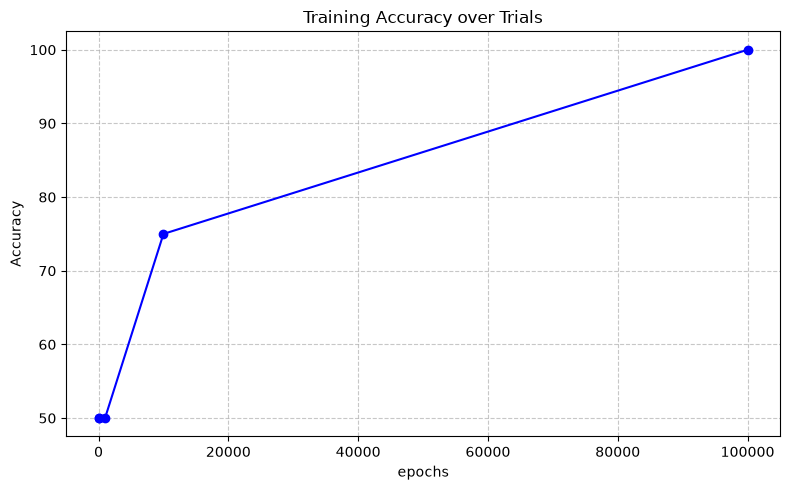

In [91]:
torch.manual_seed(42)
model = AND()

optimizer = optim.SGD(model.parameters(), lr=0.001)
base_epoch = 1
trials = 5
trial_history = []
accuracy_history = []

for trial in range(trials):
    train(optimizer, base_epoch)
    base_epoch = base_epoch*10
    current_acc = getaccuracy()
    trial_history.append(base_epoch)
    accuracy_history.append(current_acc)

plot_metrics(x=trial_history, y=accuracy_history, title="Training Accuracy over Trials", xlabel="epochs", ylabel="Accuracy")